<a href="https://colab.research.google.com/github/sasindipeiris/EN4554_deep_learning_for_vision/blob/main/220454P_a02_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment on CNNs


Name : Peiris T.P.N.S

Index number : 220454P

I acknowledge the use of Claude to assist with coding and debugging for this assignment, and I confirm that I fully understand the implemented code.

## Setup

Use CIFAR-10 (torchvision.datasets.CIFAR10): split the training set into 45k
train and 5k validation, normalize per channel with training statistics, and fix random seeds.



In [27]:
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import Optimizer
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, random_split

In [ ]:
# Fix Random seeds for Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [ ]:
raw_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)

# Split the training set into 45k train and 5k validation
generator = torch.Generator().manual_seed(42)
train_split, val_split = random_split(raw_dataset, [45000, 5000], generator=generator)

# Calculate per-channel mean and std using only the training statistics
train_data = raw_dataset.data[train_split.indices] / 255.0
mean_stats = train_data.mean(axis=(0, 1, 2))
std_stats = train_data.std(axis=(0, 1, 2))

print(f"Mean: {mean_stats} \nStd: {std_stats}")

# Normalize per channel with training statistics
base_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_stats.tolist(), std=std_stats.tolist())
])

# Instantiate seperate datasets for train and val
full_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, transform=base_transform)
full_val_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, transform=base_transform)

train_subset = Subset(full_train_dataset, train_split.indices)
val_subset = Subset(full_val_dataset, val_split.indices)

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False, num_workers=2)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=base_transform)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

100%|██████████| 170M/170M [1:00:31<00:00, 47.0kB/s]


Mean: [0.49165571 0.48233405 0.44667923] 
Std: [0.24708116 0.24350869 0.26158066]


## 1. Backpropagation

a. Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and
assemble an MLP.

In [ ]:
class Linear:
    def __init__(self, in_features, out_features, seed=42):
        torch.manual_seed(seed)
        # Kaiming initialization
        self.W = torch.randn(in_features, out_features) * (2.0 / in_features) ** 0.5
        self.b = torch.zeros(out_features)
        self.X = None
        self.grad_W = None
        self.grad_b = None

    def forward(self, X):
        self.X = X
        return X @ self.W + self.b

    def backward(self, dZ):
        self.grad_W = self.X.T @ dZ
        self.grad_b = dZ.sum(dim=0)
        dX = dZ @ self.W.T
        return dX

In [ ]:
class ReLU:
    def __init__(self):
        self.mask = None

    def forward(self, Z):
        self.mask = (Z > 0).float()
        return Z * self.mask

    def backward(self, dA):
        return dA * self.mask

In [ ]:
class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        # targets: (batch_size,) integer labels
        self.targets = targets
        # Shift logits for numerical stability
        logits_max = torch.max(logits, dim=1, keepdim=True).values
        exp_logits = torch.exp(logits - logits_max)
        self.probs = exp_logits / torch.sum(exp_logits, dim=1, keepdim=True)
        batch_size = logits.size(0)
        core_probs = self.probs[torch.arange(batch_size), targets]
        loss = -torch.log(core_probs + 1e-9).mean()
        return loss

    def backward(self):
        batch_size = self.probs.size(0)
        dZ = self.probs.clone()
        dZ[torch.arange(batch_size), self.targets] -= 1.0
        dZ = dZ / batch_size
        return dZ

In [ ]:
class CustomMLP:
    def __init__(self, in_dim=3072, hidden_dim=256, out_dim=10):
        self.fc1 = Linear(in_dim, hidden_dim)
        self.relu = ReLU()
        self.fc2 = Linear(hidden_dim, out_dim)
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, X):
        Z1 = self.fc1.forward(X)
        A1 = self.relu.forward(Z1)
        logits = self.fc2.forward(A1)
        return logits

    def backward(self):
        d_logits = self.criterion.backward()
        d_A1 = self.fc2.backward(d_logits)
        d_Z1 = self.relu.backward(d_A1)
        self.fc1.backward(d_Z1)

b. Verify your gradients against autograd and against centred finite differences; report the relative errors. Use
torch.allclose to check whether the gradients match

In [ ]:
def check_gradients():
    torch.manual_seed(42)
    X = torch.randn(4, 10, dtype=torch.float64) # Use float64 for finite differences precision
    y = torch.randint(0, 5, (4,))

    # 1. Custom Setup
    linear = Linear(10, 5)
    linear.W = linear.W.to(torch.float64)
    linear.b = linear.b.to(torch.float64)
    criterion = SoftmaxCrossEntropy()

    # Forward and manual backward
    logits_custom = linear.forward(X)
    loss_custom = criterion.forward(logits_custom, y)
    dZ = criterion.backward()
    linear.backward(dZ)
    grad_W_custom = linear.grad_W.clone()

    # 2. Autograd Setup
    W_auto = linear.W.clone().requires_grad_(True)
    b_auto = linear.b.clone().requires_grad_(True)

    logits_auto = X @ W_auto + b_auto
    loss_auto = F.cross_entropy(logits_auto, y)
    loss_auto.backward()
    grad_W_auto = W_auto.grad.clone()

    # 3. Finite Differences Setup
    epsilon = 1e-5
    grad_W_fd = torch.zeros_like(linear.W)

    for i in range(linear.W.size(0)):
        for j in range(linear.W.size(1)):
            W_plus = linear.W.clone()
            W_plus[i, j] += epsilon
            loss_plus = criterion.forward(X @ W_plus + linear.b, y)

            W_minus = linear.W.clone()
            W_minus[i, j] -= epsilon
            loss_minus = criterion.forward(X @ W_minus + linear.b, y)

            grad_W_fd[i, j] = (loss_plus - loss_minus) / (2 * epsilon)


    rel_error_auto = torch.norm(grad_W_custom - grad_W_auto) / torch.norm(grad_W_auto)
    rel_error_fd = torch.norm(grad_W_custom - grad_W_fd) / torch.norm(grad_W_fd)

    match_auto = torch.allclose(grad_W_custom, grad_W_auto, atol=1e-5)
    match_fd = torch.allclose(grad_W_custom, grad_W_fd, atol=1e-5)

    print(f"Match Autograd: {match_auto}, Relative Error: {rel_error_auto.item():.2e}")
    print(f"Match Finite Diff: {match_fd}, Relative Error: {rel_error_fd.item():.2e}")

check_gradients()

Match Autograd: True, Relative Error: 8.41e-17
Match Finite Diff: True, Relative Error: 3.29e-08


**Interpretation**

- The custom backpropagation implementation is mathematically correct.

- The relative error against PyTorch's Autograd is practically zero ($8.41 \times 10^{-17}$) and the relative error against centered finite differences is slightly higher ($3.29 \times 10^{-8}$) but still extremely small; this minor deviation is completely expected due to the inherent numerical approximation and precision limits of the finite difference method.

- Both tests successfully pass the `torch.allclose` verification.

c. Train it with SGD on flattened CIFAR-10 images; plot the loss and report validation accuracy.

Epoch [1/10] | Training Loss: 1.8674
Epoch [2/10] | Training Loss: 1.5368
Epoch [3/10] | Training Loss: 1.4586
Epoch [4/10] | Training Loss: 1.4007
Epoch [5/10] | Training Loss: 1.3523
Epoch [6/10] | Training Loss: 1.3258
Epoch [7/10] | Training Loss: 1.2772
Epoch [8/10] | Training Loss: 1.2713
Epoch [9/10] | Training Loss: 1.2264
Epoch [10/10] | Training Loss: 1.2053


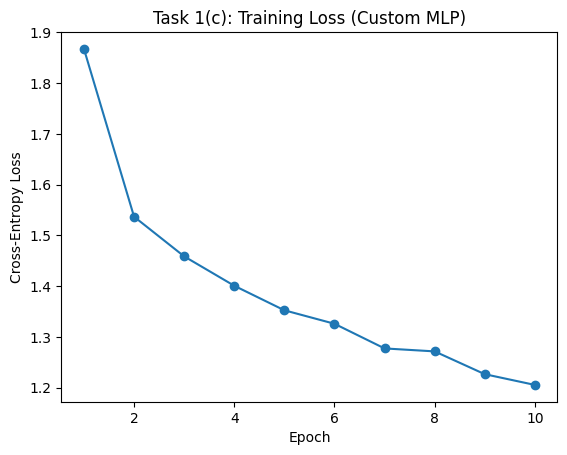

Final Validation Accuracy: 45.16%


In [ ]:
import matplotlib.pyplot as plt

def train_custom_mlp(train_loader, val_loader, epochs=10, lr = 0.1):
  model = CustomMLP(in_dim=3072,hidden_dim=256,out_dim=10)
  train_losses = []

  for epoch in range(epochs):
    epoch_loss = 0.0

    # Training loop
    for images, labels in train_loader:
      X = images.view(images.size(0), -1)

      # Forward pass
      logits = model.forward(X)
      loss = model.criterion.forward(logits, labels)
      epoch_loss += loss.item()

      # Backward pass
      model.backward()

      # SGD step
      model.fc1.W -= lr * model.fc1.grad_W
      model.fc1.b -= lr * model.fc1.grad_b
      model.fc2.W -= lr * model.fc2.grad_W
      model.fc2.b -= lr * model.fc2.grad_b

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}] | Training Loss: {avg_loss:.4f}")

  correct = 0
  total = 0
  for images, labels in val_loader:
    X = images.view(images.size(0), -1)
    logits = model.forward(X)
    predictions = torch.argmax(logits, dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

  val_acc = 100 * correct / total

  plt.plot(range(1, epochs+1), train_losses, marker='o')
  plt.title("Task 1(c): Training Loss (Custom MLP)")
  plt.xlabel("Epoch")
  plt.ylabel("Cross-Entropy Loss")
  plt.show()

  print(f"Final Validation Accuracy: {val_acc:.2f}%")

train_custom_mlp(train_loader, val_loader, epochs=10, lr=0.1)

**Interpretation**

 - The training loss curve demonstrates a steady and consistent decline from 1.86 to 1.20 over the 10 epochs. This confirms that the custom SGD implementation and manual backpropagation function correctly to minimize the cross entropy error.

 - However, the final validation accuracy plateaus around 45%. This relatively low accuracy is expected because a MLP requires flattening the 32x32 CIFAR-10 images into 1D vectors, which destroys critical 2D spatial relationships and lacks translation invariance.

d. For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.

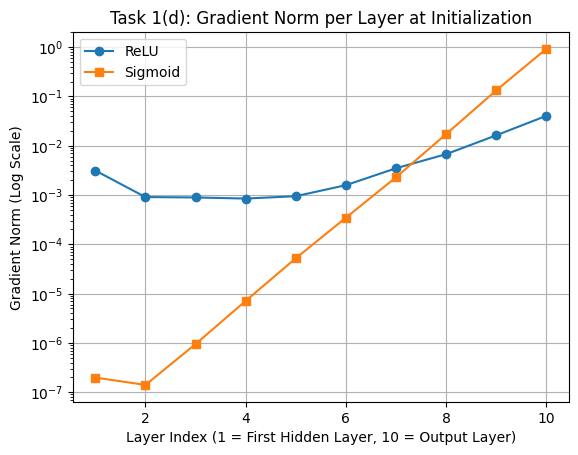

In [ ]:
def analyze_gradients():
  def build_10_layer_mlp(activation):
    layers = []
    in_dim = 3072
    for _ in range(9):
      layers.append(nn.Linear(in_dim,256))
      layers.append(activation)
      in_dim = 256
    layers.append(nn.Linear(in_dim,10))
    return nn.Sequential(*layers)

  torch.manual_seed(42)
  relu_model = build_10_layer_mlp(nn.ReLU())
  sigmoid_model = build_10_layer_mlp(nn.Sigmoid())

  X = torch.randn(32,3072)
  y = torch.randint(0,10,(32,))
  criterion = nn.CrossEntropyLoss()

  criterion(relu_model(X),y).backward()
  criterion(sigmoid_model(X),y).backward()

  relu_norms = [layer.weight.grad.norm().item() for layer in relu_model if isinstance(layer, nn.Linear)]
  sigmoid_norms = [layer.weight.grad.norm().item() for layer in sigmoid_model if isinstance(layer, nn.Linear)]

  layer_indices = list(range(1, 11))
  plt.plot(layer_indices, relu_norms, label='ReLU', marker='o')
  plt.plot(layer_indices, sigmoid_norms, label='Sigmoid', marker='s')
  plt.yscale('log')
  plt.title("Task 1(d): Gradient Norm per Layer at Initialization")
  plt.xlabel("Layer Index (1 = First Hidden Layer, 10 = Output Layer)")
  plt.ylabel("Gradient Norm (Log Scale)")
  plt.legend()
  plt.grid(True)
  plt.show()

analyze_gradients()

**Interpretation**

- The above plot clearly demonstrates the vanishing gradient problem.

- For the Sigmoid network, the gradient norm drops exponentially as it flows backward from the output layer (Layer 10) to the first hidden layer (Layer 1).This occurs because the derivative of the Sigmoid function never exceeds 0.25. When these small derivatives are repeatedly multiplied via the chain rule during backpropagation, the learning signal shrinks to near zero.

- In contrast, the ReLU network maintains a stable gradient norm across all layers. Because the derivative of an active ReLU neuron is exactly 1.0 it preserves the magnitude of the gradients.

# 2. Optimizers

In [ ]:
class CustomSGDMomentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        defaults = dict(lr=lr, momentum=momentum)
        super().__init__(params, defaults)

    def step(self, closure=None):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad.data
                state = self.state[p]

                # Initialize the momentum buffer on the first step
                if 'momentum_buffer' not in state:
                    state['momentum_buffer'] = torch.zeros_like(p.data)

                # v_t = mu * v_{t-1} + g_t
                buf = state['momentum_buffer']
                buf.mul_(group['momentum']).add_(grad)

                # theta_t = theta_{t-1} - lr * v_t
                p.data.add_(buf, alpha=-group['lr'])

In [ ]:
class CustomAdam(Optimizer):
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8):
        defaults = dict(lr=lr, betas=betas, eps=eps)
        super().__init__(params, defaults)

    def step(self, closure=None):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad.data
                state = self.state[p]

                # Initialize step count and exponential moving averages
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p.data)
                    state['exp_avg_sq'] = torch.zeros_like(p.data)

                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                beta1, beta2 = group['betas']
                state['step'] += 1

                # 1. Update biased first moment estimate: m_t = beta1 * m_{t-1} + (1 - beta1) * g_t
                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)

                # 2. Update biased second raw moment estimate: v_t = beta2 * v_{t-1} + (1 - beta2) * g_t^2
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                # 3. Compute bias corrections
                bias_correction1 = 1 - beta1 ** state['step']
                bias_correction2 = 1 - beta2 ** state['step']

                # 4. Apply updates
                # Adjusted learning rate to bake in the first moment bias correction
                step_size = group['lr'] / bias_correction1

                # Denominator applying the second moment bias correction
                denom = (exp_avg_sq.sqrt() / torch.sqrt(torch.tensor(bias_correction2))) + group['eps']

                # theta_t = theta_{t-1} - step_size * (m_t / denom)
                p.data.addcdiv_(exp_avg, denom, value=-step_size)


In [ ]:
def verify_optimizers():
  torch.manual_seed(42)
  X = torch.randn(10,5)
  y = torch.randn(10,1)

  def get_model():
    torch.manual_seed(42)
    return torch.nn.Linear(5,1)

  # Verify SGD with momentum
  model_custom = get_model()
  model_torch = get_model()

  opt_custom = CustomSGDMomentum(model_custom.parameters(), lr=0.1, momentum=0.9)
  opt_torch = torch.optim.SGD(model_torch.parameters(), lr=0.1, momentum=0.9)

  for _ in range(5):
    opt_custom.zero_grad()
    loss_c = torch.nn.functional.mse_loss(model_custom(X),y)
    loss_c.backward()
    opt_custom.step()

    opt_torch.zero_grad()
    loss_t = torch.nn.functional.mse_loss(model_torch(X), y)
    loss_t.backward()
    opt_torch.step()

  sgd_match = torch.allclose(model_custom.weight, model_torch.weight, atol=1e-5)
  print(f"Custom SGD Momentum matches torch.optim.SGD: {sgd_match}")

  # Verify Adam Optimizer
  model_custom = get_model()
  model_torch = get_model()

  opt_custom = CustomAdam(model_custom.parameters(), lr=0.1)
  opt_torch = torch.optim.Adam(model_torch.parameters(), lr=0.1)

  for _ in range(5):
      # Custom Step
      opt_custom.zero_grad()
      loss_c = torch.nn.functional.mse_loss(model_custom(X), y)
      loss_c.backward()
      opt_custom.step()

      # PyTorch Step
      opt_torch.zero_grad()
      loss_t = torch.nn.functional.mse_loss(model_torch(X), y)
      loss_t.backward()
      opt_torch.step()

  adam_match = torch.allclose(model_custom.weight, model_torch.weight, atol=1e-5)
  print(f"Custom Adam matches torch.optim.Adam: {adam_match}")

verify_optimizers()


Custom SGD Momentum matches torch.optim.SGD: True
Custom Adam matches torch.optim.Adam: True


b. On $f(x, y) = \frac{1}{2}(x^2 + 50y^2)$, plot the trajectories of SGD, SGD with momentum, and Adam. Use contour to plot the contours of $f(x, y)$ and explain the differences.

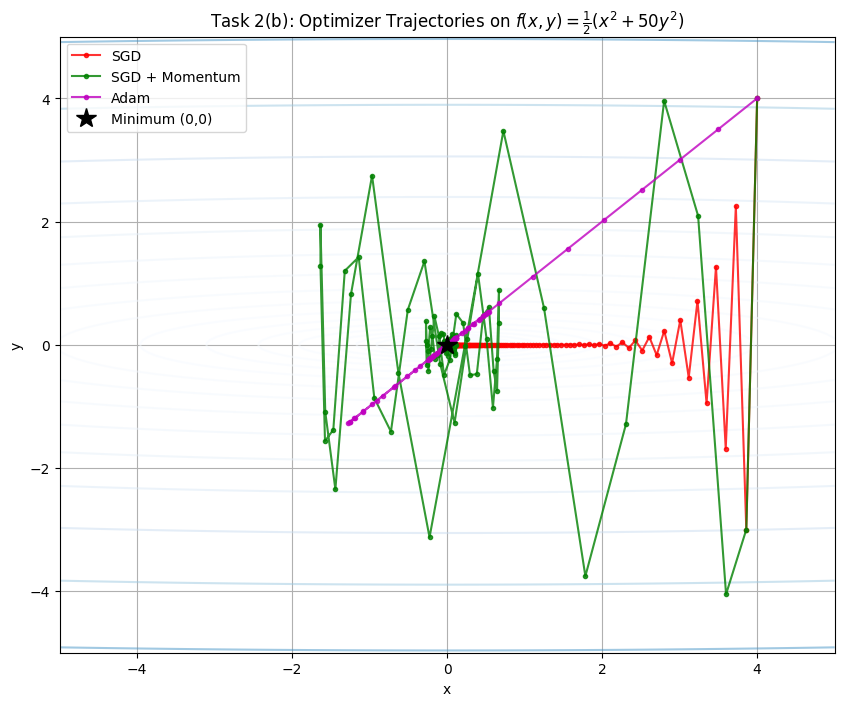

In [ ]:
def f_xy(x, y):
    return 0.5 * (x**2 + 50 * y**2)

def get_trajectory(optimizer_class, start_pos, lr, num_steps=100, **kwargs):
  pos = torch.tensor(start_pos, dtype=torch.float32, requires_grad=True)
  optimizer = optimizer_class([pos], lr=lr, **kwargs)
  trajectory = [pos.detach().numpy().copy()]

  for _ in range(num_steps):
      optimizer.zero_grad()
      loss = f_xy(pos[0], pos[1])
      loss.backward()
      optimizer.step()
      trajectory.append(pos.detach().numpy().copy())

  return np.array(trajectory)

start_pos = [4.0, 4.0]

traj_sgd = get_trajectory(torch.optim.SGD, start_pos, lr=0.035)
traj_momentum = get_trajectory(torch.optim.SGD, start_pos, lr=0.035, momentum=0.9)
traj_adam = get_trajectory(torch.optim.Adam, start_pos, lr=0.5)

x_grid = np.linspace(-5, 5, 200)
y_grid = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x_grid, y_grid)
Z = 0.5 * (X**2 + 50 * Y**2)

plt.figure(figsize=(10, 8))
plt.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='Blues', alpha=0.5)

plt.plot(traj_sgd[:, 0], traj_sgd[:, 1], 'r.-', label='SGD', alpha=0.8)
plt.plot(traj_momentum[:, 0], traj_momentum[:, 1], 'g.-', label='SGD + Momentum', alpha=0.8)
plt.plot(traj_adam[:, 0], traj_adam[:, 1], 'm.-', label='Adam', alpha=0.8)

plt.plot(0, 0, 'k*', markersize=15, label='Minimum (0,0)')
plt.title("Task 2(b): Optimizer Trajectories on $f(x,y) = \\frac{1}{2}(x^2 + 50y^2)$")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

**Interpretation**

* **SGD:** Results in severe oscillations along the high curvature axis (y-axis). To prevent divergence in the y-direction, a small learning rate must be used.

* **SGD + Momentum:** Momentum initially causes large overshooting and wide oscillations. However, the opposing y-gradients eventually cancel each other out in the momentum buffer.

* **Adam:** Adam takes the most direct, nearly straight path to the minimum. By maintaining adaptive learning rates for each parameter, it mathematically scales down the massive y-updates and scales up the tiny x-updates.

c.Train a small CNN with each optimizer (plain SGD, SGD with momentum, Adam) at three learning rates
each. Plot validation accuracy versus learning rate and the training loss at the best rate. Discuss sensitivity.


In [ ]:
class SmallCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.features = nn.Sequential(
        nn.Conv2d(3,16,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2),
        nn.Conv2d(16,32,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2,2)
    )
    self.classifier = nn.Linear(32*8*8,10)

  def forward(self,x):
    x = self.features(x)
    x = x.view(x.size(0),-1)
    x = self.classifier(x)
    return x

In [ ]:
def train_eval_model(optimizer_name, lr, train_loader, val_loader, epochs=5, device='cuda'):
  model = SmallCNN().to(device)
  criterion = nn.CrossEntropyLoss()

  if optimizer_name == 'SGD':
        optimizer = optim.SGD(model.parameters(), lr=lr)
  elif optimizer_name == 'SGD+Momentum':
      optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
  elif optimizer_name == 'Adam':
      optimizer = optim.Adam(model.parameters(), lr=lr)

  train_losses = []

  for epoch in range(epochs):
      model.train()
      epoch_loss = 0.0
      for inputs, labels in train_loader:
          inputs, labels = inputs.to(device), labels.to(device)
          optimizer.zero_grad()
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          loss.backward()
          optimizer.step()
          epoch_loss += loss.item()
      train_losses.append(epoch_loss / len(train_loader))

  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
      for inputs, labels in val_loader:
          inputs, labels = inputs.to(device), labels.to(device)
          outputs = model(inputs)
          _, predicted = torch.max(outputs.data, 1)
          total += labels.size(0)
          correct += (predicted == labels).sum().item()

  val_acc = 100 * correct / total
  return val_acc, train_losses






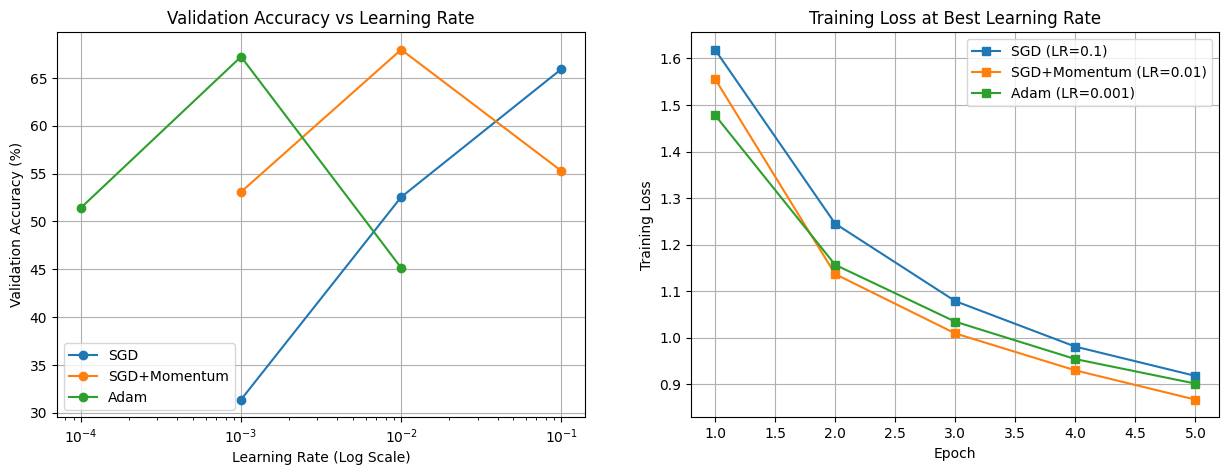

In [ ]:
def run_task_2c(train_loader, val_loader):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    configs = {
        'SGD': [0.1, 0.01, 0.001],
        'SGD+Momentum': [0.1, 0.01, 0.001],
        'Adam': [0.01, 0.001, 0.0001]
    }

    results = {}
    best_losses = {}

    for opt_name, lrs in configs.items():
        results[opt_name] = {'lrs': lrs, 'accs': []}
        best_acc = 0

        for lr in lrs:
            val_acc, train_losses = train_eval_model(opt_name, lr, train_loader, val_loader, epochs=5, device=device)
            results[opt_name]['accs'].append(val_acc)

            if val_acc > best_acc:
                best_acc = val_acc
                best_losses[opt_name] = (lr, train_losses)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    for opt_name in results:
        ax1.plot(results[opt_name]['lrs'], results[opt_name]['accs'], marker='o', label=opt_name)
    ax1.set_xscale('log')
    ax1.set_title('Validation Accuracy vs Learning Rate')
    ax1.set_xlabel('Learning Rate (Log Scale)')
    ax1.set_ylabel('Validation Accuracy (%)')
    ax1.legend()
    ax1.grid(True)

    for opt_name, (best_lr, losses) in best_losses.items():
        ax2.plot(range(1, 6), losses, marker='s', label=f"{opt_name} (LR={best_lr})")
    ax2.set_title('Training Loss at Best Learning Rate')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Training Loss')
    ax2.legend()
    ax2.grid(True)

    plt.show()

run_task_2c(train_loader, val_loader)

**Interpretation**

* **Sensitivity to Learning Rate:** The above plot shows that different optimizers require different learning rate scales. Plain SGD performs best at a high learning rate of $10^{-1}$, as it lacks acceleration mechanisms and needs larger steps to make progress. SGD with Momentum peaks at $10^{-2}$, while Adam peaks at an even smaller rate of $10^{-3}$. If Adam is given a learning rate that is too high (e.g., $10^{-2}$), its validation accuracy drops significantly,highlighting that its adaptive moment estimation can become unstable if the base step size is too large.

* **Convergence at Best Rate:** When operating at their respective optimal learning rates, all three optimizers successfully minimize the training loss over the 5 epochs. SGD with Momentum achieves the lowest final training loss showing how accumulating past gradients helps accelerate convergence compared to the plain SGD.

## 3. Regularization and residual connections

a.Train a small CNN with batch norm on 5k training images. Compare: baseline, weight decay, dropout,
flip+crop, cutout, mixup, and all combined (implement cutout and mixup yourself). Tabulate train accuracy,
validation accuracy, and their gap; plot the curves

In [ ]:
class Cutout(object):
  def __init__(self, length=16):
    self.length = length # Size of the square patch to remove

  def __call__(self,img):
    h, w = img.size(1), img.size(2)
    mask = np.ones((h,w), np.float32)

    # Select random center coordinates for the cutout patch
    y = np.random.randint(h)
    x = np.random.randint(w)

    # Calculate boundaries to stay within image dimensions
    y1 = np.clip(y - self.length // 2, 0, h)
    y2 = np.clip(y + self.length // 2, 0, h)
    x1 = np.clip(x - self.length // 2, 0, w)
    x2 = np.clip(x + self.length // 2, 0, w)

    mask[y1:y2, x1:x2] = 0.
    mask = torch.from_numpy(mask)
    mask = mask.expand_as(img)

    img = img * mask
    return img

In [ ]:

def mixup_data(x, y, alpha=1.0):
    # Sample a mixing parameter lambda from the Beta distribution
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1

    batch_size = x.size()[0]
    # Create a randomly shuffled index of the batch
    index = torch.randperm(batch_size).to(x.device)

    # Linearly interpolate between the original images and the shuffled images
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]

    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

In [ ]:
class SmallCNN_BN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        self.use_dropout = use_dropout
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16), # Batch Norm added after convolution
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32), # Batch Norm added after convolution
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.drop = nn.Dropout(0.5) # Dropout layer for regularization
        self.classifier = nn.Linear(32 * 8 * 8, 10)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        if self.use_dropout:
            x = self.drop(x)
        return self.classifier(x)

      Method  Train Acc (%)  Val Acc (%)  Gap (%)
    Baseline          97.64        54.54    43.10
Weight Decay          96.26        55.04    41.22
     Dropout          81.42        60.72    20.70
   Flip+Crop          62.30        62.32    -0.02
      Cutout          77.96        57.04    20.92
       Mixup          82.68        54.14    28.54
All Combined          46.44        49.56    -3.12


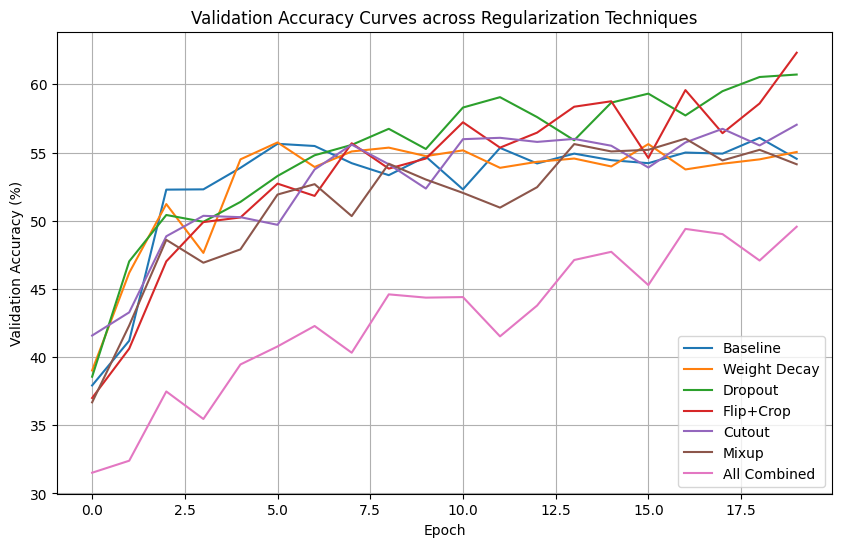

In [ ]:
def run_regularization_experiments(full_train_dataset,val_dataset,base_transform):
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

  torch.manual_seed(42)
  indices_5k = torch.randperm(len(full_train_dataset))[:5000].tolist()

  transform_flip_crop = transforms.Compose([
      transforms.RandomCrop(32, padding=4),
      transforms.RandomHorizontalFlip(),
      base_transform
  ])

  transform_cutout = transforms.Compose([
      base_transform,
      Cutout(length=16)
  ])

  transform_all = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        base_transform,
        Cutout(length=16)
    ])

  configs = {
        'Baseline': {'wd': 0, 'drop': False, 'aug': base_transform, 'mixup': False},
        'Weight Decay': {'wd': 1e-4, 'drop': False, 'aug': base_transform, 'mixup': False},
        'Dropout': {'wd': 0, 'drop': True, 'aug': base_transform, 'mixup': False},
        'Flip+Crop': {'wd': 0, 'drop': False, 'aug': transform_flip_crop, 'mixup': False},
        'Cutout': {'wd': 0, 'drop': False, 'aug': transform_cutout, 'mixup': False},
        'Mixup': {'wd': 0, 'drop': False, 'aug': base_transform, 'mixup': True},
        'All Combined': {'wd': 1e-4, 'drop': True, 'aug': transform_all, 'mixup': True}
    }

  results = []
  histories = {}

  for name, cfg in configs.items():
      train_subset = Subset(full_train_dataset, indices_5k)
      train_subset.dataset.transform = cfg['aug']
      train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
      val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

      model = SmallCNN_BN(use_dropout=cfg['drop']).to(device)
      optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=cfg['wd'])
      criterion = nn.CrossEntropyLoss()

      val_accs = []
      for epoch in range(20):
          model.train()
          for inputs, labels in train_loader:
              inputs, labels = inputs.to(device), labels.to(device)
              optimizer.zero_grad()

              if cfg['mixup']:
                  inputs, labels_a, labels_b, lam = mixup_data(inputs, labels)
                  outputs = model(inputs)
                  loss = mixup_criterion(criterion, outputs, labels_a, labels_b, lam)
              else:
                  outputs = model(inputs)
                  loss = criterion(outputs, labels)

              loss.backward()
              optimizer.step()

          model.eval()
          correct, total, train_correct, train_total = 0, 0, 0, 0
          with torch.no_grad():
              for inputs, labels in train_loader:
                  inputs, labels = inputs.to(device), labels.to(device)
                  _, pred = torch.max(model(inputs).data, 1)
                  train_total += labels.size(0)
                  train_correct += (pred == labels).sum().item()

              for inputs, labels in val_loader:
                  inputs, labels = inputs.to(device), labels.to(device)
                  _, pred = torch.max(model(inputs).data, 1)
                  total += labels.size(0)
                  correct += (pred == labels).sum().item()
          val_accs.append(100 * correct / total)

      train_acc = 100 * train_correct / train_total
      val_acc = val_accs[-1]
      gap = train_acc - val_acc
      results.append((name, train_acc, val_acc, gap))
      histories[name] = val_accs

  df = pd.DataFrame(results, columns=['Method', 'Train Acc (%)', 'Val Acc (%)', 'Gap (%)'])
  print(df.to_string(index=False))

  plt.figure(figsize=(10, 6))
  for name, accs in histories.items():
      plt.plot(accs, label=name)
  plt.title('Validation Accuracy Curves across Regularization Techniques')
  plt.xlabel('Epoch')
  plt.ylabel('Validation Accuracy (%)')
  plt.legend()
  plt.grid(True)
  plt.show()

run_regularization_experiments(full_train_dataset, val_subset, base_transform)

**Interpretation**

* **Baseline Overfitting:** Training on a small 5k subset causes the baseline model to severely overfit, reaching a training accuracy of 97.64% but a validation accuracy of only 54.54%, leaving a massive generalization gap of 43.10%.

* **Effective Regularization:** Data augmentation (`Flip+Crop`) and `Dropout` were the most successful individual techniques. `Flip+Crop` completely eliminated the generalization gap (-0.02%) and achieved the highest validation accuracy (62.32%). `Dropout` also significantly reduced the gap (20.70%) improved validation accuracy to 60.72%.

* **Excessive Regularization (All Combined):** While individual techniques help, combining all of them (`All Combined`) causes severe underfitting. The training accuracy drops to 46.44% and validation accuracy drops to 49.56%. This demonstrates that applying too much regularization simultaneously restricts the small network's capacity to learn meaningful features from the data.

b. Build CIFAR-style plain and residual networks of depth 6n + 2 for depths 8, 20, and 56 (three stages,
channels 16/32/64, global average pooling, batch norm, Kaiming initialization). The only difference between
the two families is the shortcut. Plot the training loss versus epoch and explain.


In [31]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_shortcut=True):
        super().__init__()
        self.use_shortcut = use_shortcut

        # First convolution layer of the block
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # Second convolution layer
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # The shortcut connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x) if self.use_shortcut else 0

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # The only difference between Plain and ResNet is this addition
        if self.use_shortcut:
            out += identity

        out = self.relu(out)
        return out

In [32]:
class CIFAR_Network(nn.Module):
    def __init__(self, n, use_shortcut=True):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.in_channels = 16

        # Initial Convolution (1 layer)
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)

        # Three stages
        self.stage1 = self._make_stage(16, n, stride=1)
        self.stage2 = self._make_stage(32, n, stride=2)
        self.stage3 = self._make_stage(64, n, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 10)

        # Kaiming Initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_stage(self, out_channels, blocks, stride):
        layers = []
        # First block handles the dimension changes (if any)
        layers.append(BasicBlock(self.in_channels, out_channels, stride, self.use_shortcut))
        self.in_channels = out_channels
        # Remaining blocks use stride 1
        for _ in range(1, blocks):
            layers.append(BasicBlock(out_channels, out_channels, 1, self.use_shortcut))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [33]:
def train_network(model, train_loader, epochs=20):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    losses = []
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_loader))
    return losses

In [ ]:
def run_task_3b(train_loader):
    depths = {8: 1, 20: 3, 56: 9}
    results = {'Plain': {}, 'ResNet': {}}

    for depth, n in depths.items():
        print(f"Training Plain-{depth}...")
        plain_net = CIFAR_Network(n=n, use_shortcut=False)
        results['Plain'][depth] = train_network(plain_net, train_loader, epochs=20)

        print(f"Training ResNet-{depth}...")
        res_net = CIFAR_Network(n=n, use_shortcut=True)
        results['ResNet'][depth] = train_network(res_net, train_loader, epochs=20)

    # Plotting
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    for depth in depths.keys():
        ax1.plot(results['Plain'][depth], label=f'Plain-{depth}', marker='o')
        ax2.plot(results['ResNet'][depth], label=f'ResNet-{depth}', marker='s')

    ax1.set_title('Task 3(b): Training Loss (Plain Networks)')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss')
    ax1.legend()
    ax1.grid(True)

    ax2.set_title('Task 3(b): Training Loss (Residual Networks)')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Training Loss')
    ax2.legend()
    ax2.grid(True)

    plt.show()

run_task_3b(train_loader)

Training Plain-8...
Training ResNet-8...
Training Plain-20...
Training ResNet-20...
Training Plain-56...


## 4. CNN

Design the best CNN you can with at most 500k parameters and at most 20 training epochs. Tune on the
validation split. Report an ablation of at least three design choices (e.g., shortcut, augmentation, weight decay,
optimizer), and the test accuracy of your final model, evaluated once.


In [ ]:
# Design an optimal CNN strictly under the 500k parameter limit
class OptimalCNN(nn.Module):
    def __init__(self, use_shortcut=True, dropout_rate=0.3):
        super().__init__()
        self.use_shortcut = use_shortcut

        # Block 1: 3 channels to 32 channels (~864 params)
        self.prep = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # Block 2: 32 channels to 64 channels + Spatial reduction (~18k params)
        self.layer1 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2) # Reduces 32x32 to 16x16
        )

        # Block 3: 64 channels to 128 channels + Spatial reduction (~73k params)
        self.layer2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2) # Reduces 16x16 to 8x8
        )

        # Block 4: Residual Block keeping 128 channels (~294k params)
        self.res_conv1 = nn.Conv2d(128, 128, 3, padding=1, bias=False)
        self.res_bn1 = nn.BatchNorm2d(128)
        self.res_conv2 = nn.Conv2d(128, 128, 3, padding=1, bias=False)
        self.res_bn2 = nn.BatchNorm2d(128)
        self.relu = nn.ReLU(inplace=True)

        # Regularization and Classification (~1.2k params)
        self.drop = nn.Dropout(dropout_rate)
        self.pool = nn.AdaptiveAvgPool2d((1, 1)) # Reduces 8x8 to 1x1
        self.classifier = nn.Linear(128, 10)

        # Total parameters: ~387,000 (Safely below the 500k limit)

    def forward(self, x):
        x = self.prep(x)
        x = self.layer1(x)
        x = self.layer2(x)

        # Ablation toggle for the residual shortcut
        if self.use_shortcut:
            identity = x
            out = self.relu(self.res_bn1(self.res_conv1(x)))
            out = self.res_bn2(self.res_conv2(out))
            x = self.relu(out + identity)
        else:
            x = self.relu(self.res_bn1(self.res_conv1(x)))
            x = self.relu(self.res_bn2(self.res_conv2(x)))

        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.drop(x)
        return self.classifier(x)